## Summary

We present a reusable, cloud-scalable pipeline that pairs Cellpose-SAM segmentation with on-demand GPU compute for single-cell phenotyping of high-content microscopy, demonstrated on a two-species yeast panel (*S. cerevisiae* versus *S. pombe*).

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on Airtable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

High-content microscopy can generate more images than a single workstation can process in a reasonable amount of time. Segmentation is the most computationally intensive step, but turning raw images into quantitative phenotypes also involves transferring large volumes of image data, provisioning GPUs, running sophisticated segmentation algorithms, and collecting standardized per-cell measurements. In this pub, we present a worked example that handles this entire workflow, pairing Cellpose-SAM [@pachitariu2025cellpose] with on-demand compute to scale segmentation across cloud GPUs. This shortens the path from imaging to biological interpretation and gives readers a pattern they can adapt to their own data rather than assemble from scratch. On a two-species yeast panel, we show:

1. Cellpose-SAM, combined with cloud GPU compute, can efficiently scale single-cell phenotyping across large microscopy datasets.
2. The phenotyping outputs derived from the segmentation resolve gross morphological differences between populations.

This pub is aimed at researchers developing high-throughput microscopy workflows or deciding how to scale segmentation and phenotyping. The analysis that follows runs on a dataset of two yeast species (*S. cerevisiae* and *S. pombe*), which is useful for validating the pipeline rather than a source of new biological conclusions. The workflow isn't yeast-specific — the same steps of file I/O, segmentation, parallel execution, and per-cell measurement carry over to other images, though it's best suited to imaging individual cells, such as unicellular organisms or dissociated cell populations, where cells can be segmented cleanly. For background on the tools we build on, see the [Cellpose-SAM documentation](https://cellpose.readthedocs.io/en/latest/) and the [Modal documentation](https://modal.com/docs).

## The pipeline

### How the pieces fit together

At a high level, the pipeline turns raw images into quantitative phenotypes, parallelizing the heavy segmentation step across on-demand cloud GPUs (@fig-workflow).

:::{#fig-workflow fig-cap="Overview of the cloud-scaled, single-cell phenotyping pipeline. Raw microscopy images (input) are segmented using Cellpose-SAM, with one worker per image, distributed across a GPU cluster to process images in parallel. Segmentation produces a label mask per image (output), from which per-cell shape features are measured (phenotyping) and written as CSVs. Pooling these per-cell measurements and matching them to the plate map, which links each well to its sample metadata, yields the single-cell dataset used for the downstream morphology analysis. The two rows illustrate the two-species yeast panel — ovoid *S. cerevisiae* (top, yellow-green) and rod-shaped *S. pombe* (bottom, blue-green)." fig-alt="Left-to-right schematic. Two stacks of raw images — ovoid budding yeast above, rod-shaped fission yeast below — enter a 2-by-4 grid of Cellpose-SAM jobs on a GPU cluster and come out as matching mask stacks. Those feed a stack of per-cell CSV measurements and a plate map of sample wells, which together feed a scatter plot with two distinct clusters."}
![](assets/fig1-workflow.png)
:::

The pipeline runs through the following stages:

1. **Input.** Raw microscopy images live in object storage (S3). `arcadia-microscopy-tools` reads the ND2s and parses the metadata we need.
2. **Segmentation.** Cellpose-SAM segments and labels the cells in each image. We run one GPU worker per image so the plate processes in parallel, reading from and writing to shared cloud storage.
3. **Output.** Each worker writes a labeled TIFF for the segmentation mask and an overlay of the cell outlines we use to assess segmentation quality.
4. **Phenotyping.** From the masks, we measure per-cell shape features and write them as CSVs.
5. **Analysis.** Those tables are pooled and joined to the plate map so we can compare morphology across strains.

The code cells in @sec-segmentation execute each stage of the pipeline, so a reader can clone the repo and either reproduce our results or swap in their own dataset. See the [setup guide](pages/SETUP.qmd) for more information.

### A two-species yeast panel

To validate the pipeline, we acquired brightfield images of two diploid yeasts chosen for visually distinct morphologies — ovoid budding yeast (*S. cerevisiae* BY4743) and rod-shaped fission yeast (*S. pombe* SP286) — across 16 wells of a 384-well plate (@tbl-plate-map). We imaged each well in a 2×2 grid, yielding 64 fields of view. Cell culture and acquisition settings are in @sec-methods.

| Species | Strain | Wells |
| --- | --- | --- |
| *S. cerevisiae* | `BY4743` | K01–K04, L01–L04 |
| *S. pombe* | `SP286` | K05–K08, L05–L08 |

: Plate map for the two-species panel {#tbl-plate-map}

At 64 images, the plate is big enough to show cloud GPU scaling in action but small enough to run and inspect end to end. And with eight replicate wells per species, we can work at the well level — comparing per-well medians across the 16 wells rather than treating every cell as an independent measurement.

The metadata from a representative ND2 file (well K01; @tbl-nd2-meta) records the optics and pixel size used across the plate. We use that pixel size to convert the downstream morphology measurements to micrometers.

::: {.callout-note title="First local run downloads the published dataset" collapse="true"}
Without Modal + S3 access, the next cell downloads and extracts the public archive ([10.5281/zenodo.23377605](https://doi.org/10.5281/zenodo.23377605); 764 MB compressed, 2.3 GB unpacked) into `datasets/<id>/`. This one-time download is expected to take several minutes, although automated data fetching via Zenodo can be highly unstable due to aggressive API rate limits and frequent server connection resets.

If the in-notebook Zenodo fetch errors or times out, download `<id>.zip` directly from the public archive into `datasets/<id>/`, and re-run the cell. Doing so will bypass the automatic download attempt.
:::

In [1]:
# | code-fold: true
# | code-summary: "Code to load the example ND2 and extract metadata"
# | label: tbl-nd2-meta
# | tbl-cap: "Acquisition metadata from a representative brightfield ND2 file."

import pandas as pd
from analysis.dataset import default_dataset_dir, ensure_raw_nd2
from arcadia_microscopy_tools.nikon import parse_nd2

DATASET_ID = "20260611_141152_330"
EXAMPLE_ND2 = "WellK01_PointK01_0000_Channelbrightfield_Seq0000.nd2"
DATASET_DIR = default_dataset_dir(DATASET_ID)
nd2_path = ensure_raw_nd2(DATASET_ID, EXAMPLE_ND2, DATASET_DIR)

meta = parse_nd2(nd2_path)
cm = meta.channel_metadata_list[0]

pd.DataFrame.from_dict(
    {
        "file": nd2_path.name,
        "channel": cm.channel.name,
        "objective": cm.optics.objective,
        "magnification": cm.optics.magnification,
        "NA": cm.optics.numerical_aperture,
        "pixel_size_um": cm.resolution.xy_step_um,
        "exposure_s": cm.acquisition.exposure_time_s,
    },
    orient="index",
    columns=["value"],
)

,value
file,WellK01_PointK01_0000_Channelbrightfield_Seq00...
channel,BRIGHTFIELD
objective,PLAN APO λD 40x OFN25 DIC N2
magnification,40
NA,0.95
pixel_size_um,0.1625
exposure_s,0.01


### Single-cell segmentation at scale {#sec-segmentation}

This section covers the core steps of the pipeline: segmenting every image across the plate and extracting per-cell measurements. We first describe the processing applied to each image, then the two ways of running it — either locally or scaled across a GPU cluster.

Brightfield images are traditionally hard to segment because cells are nearly transparent, so contrast against the background is low [@wang2018yeast;@din2021segmentation]. Each image therefore goes through three steps. First, a difference-of-Gaussians bandpass filter removes background gradients and pixel-level noise while preserving features at the scale of a cell. We found empirically that this step keeps Cellpose-SAM from sporadically mislabeling background features as cells. Second, Cellpose-SAM labels each cell. Third, we measure each cell with scikit-image `regionprops` [@vanderwalt2014scikit] and convert the results to micrometers using the pixel size from the ND2 metadata. For each image, the pipeline saves a label mask, an overlay of cell outlines on the brightfield for visual QC, and a per-cell measurement table.

Because every image is processed independently, the same code runs on a laptop or across a GPU cluster. The notebook chooses automatically, so it works with or without our cloud infrastructure.

::: {.panel-tabset}

#### Scaled execution (Modal + S3)

With our cloud infrastructure, each ND2 is processed by its own GPU worker [@modal]. The worker reads the file from S3, runs Cellpose-SAM, measures the cells, renders the overlay, and writes the three artifacts back to the bucket. Because the files are independent, the plate is processed in parallel.

#### Local execution (no cloud account required)

Without a cloud account, the same Cellpose-SAM code runs locally, on CPU by default, and writes the same three artifacts to a local `derived/` folder. The published dataset — raw ND2s plus precomputed `derived/` artifacts — unpacks from the public Zenodo archive ([10.5281/zenodo.23377605](https://doi.org/10.5281/zenodo.23377605)). On CPU, images are processed one at a time, so a full-plate run is slower than the GPU version; the notebook defaults to a few local images and loads the published measurement tables for the rest of the analysis.

:::

The next code cell runs the plate through the pipeline and prints a summary of how many images finished, how many failed, and the wall-clock time. We keep Cellpose-SAM's default parameters, including `diameter=None`, which assumes a 30 px cell. The model is trained to be relatively invariant to scale for cells roughly 7.5–120 px in diameter [@pachitariu2025cellpose]. With our pixel size of 0.1625 µm, the yeast cells in our dataset span tens of pixels, well inside that range.

::: {.callout-note title="Choosing a backend and rerunning the segmentation" collapse="true"}
Set `CSCP_FORCE_LOCAL=1` to force the local path, or pass `backend="modal"` / `backend="local"` to `run_demo`. Details live in the [setup guide](pages/SETUP.qmd).

If you rerun this notebook locally, segmenting the full plate on CPU is very slow. `LIMIT` defaults to a few images on the local path (`None` on Modal). Downstream tables and QC overlays load from the published `derived/` artifacts, so you don't need to segment the whole plate to reproduce the analysis.
:::

In [2]:
# | code-fold: true
# | code-summary: "Code for processing the plate"

import time

from analysis.runner import resolve_backend, run_demo

BACKEND = "auto"
# None = every ND2. Modal runs the full plate; local compute defaults to a few images.
LIMIT = None if resolve_backend(BACKEND) == "modal" else 3
CELL_DIAMETER_PX = None

started = time.time()
run = run_demo(
    DATASET_ID,
    limit=LIMIT,
    backend=BACKEND,
    diameter=CELL_DIAMETER_PX,
)
elapsed = time.time() - started

if run.backend == "modal":
    print(f"[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/{run.output_prefix}/")
else:
    print(f"[local] Wrote artifacts to {run.output_prefix}")
print(f"Segmented {len(run.results)} image(s), {len(run.failures)} failure(s) in {elapsed:.1f}s.")

[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/datasets/20260611_141152_330/derived/
Segmented 64 image(s), 0 failure(s) in 564.3s.


### How the full plate scales

Because each image is processed independently, adding workers should shorten the run roughly proportionally. To see how closely that holds, we processed the same 64-image plate on Modal L4 GPUs at a range of worker counts, from 1 to 64 (one image per worker), and recorded wall-clock time and cost (@tbl-benchmark).^[The values in @tbl-benchmark come from `scripts/benchmark.csv`, which was generated from `scripts/benchmark.py`.] We also ran the plate once on a local Apple M3 Max GPU for comparison.

| Compute | Workers | Wall clock | Time per image | Throughput  | Cost  |
| ------- | ------- | ---------- | -------------- | ----------- | ----- |
| Cloud   | 1       | 1,609 s    | 22 s           | 2.4 img/min | $0.31 |
| Cloud   | 4       | 376 s      | 20 s           | 10 img/min  | $0.34 |
| Cloud   | 16      | 140 s      | 23 s           | 27 img/min  | $0.41 |
| Cloud   | 64      | 86 s       | 34 s           | 45 img/min  | $0.83 |
| Local   | 1       | 1,964 s    | 29 s           | 2.0 img/min | —     |

: Wall clock, per-image time (median), throughput, and cost for processing the 64-image plate on cloud (Modal, L4) and local (Apple M3 Max) GPUs {#tbl-benchmark}

Adding workers helps, but with diminishing returns. The wall clock drops from 1609 s (27 min) on a single L4 to 140 s (2.3 min) on 16 workers, then to only 86 s (1.4 min) on 64. On one worker, the images take 1,515 s of compute against 1,609 s of wall clock, so only about 90 s is startup and orchestration. On 64 workers, the median per-image time climbs from 22 s to 34 s as the shared GPU fleet gets busier, and the total wall clock (86 s) is roughly two and a half times that median — at that point the plate is waiting on cold starts and the slowest few images rather than on compute. Cost follows the same pattern: it stays near $0.30–$0.40 from 1 to 16 workers and rises to $0.83 at 64, where the extra parallelism is mostly paying for GPUs sitting idle while the slowest image finishes.

We default `max_containers` to 16, which we find is a good trade-off: it processes the plate in just over 2 min at close to the lowest cost, before the diminishing returns at higher worker counts set in. It also stays within our organization's cap of 100 concurrent GPUs on Modal's shared fleet, so it's a considerate ceiling as well as an efficient one. For comparison, the local M3 Max run (roughly 30 min) lands in the same range as a single cloud L4 — fine for a handful of images, slow for a full plate.

The scaled path is a container that reads from and writes to object storage, so the same pattern ports to AWS Batch, Slurm, or any other queue that can run a GPU container against a bucket. Modal isn't required to use the method — only to use this particular scheduler. None of these runs recorded a failure, but if a worker were to fail, `run.failures` records the image and the error, and the rest of the plate continues. The pipeline doesn't retry on its own, so we would manually re-run the missing files after debugging.

## Results

### Visual inspection

The pipeline writes a segmentation overlay for each image, with cell boundaries drawn in yellow on the brightfield. We look for failure modes that would corrupt per-cell shape: neighboring cells that have merged into a single object, an individual cell split into two, debris picked up as a cell, or real cells missed entirely. Good segmentation traces each cell tightly and exhibits none of these errors. @fig-overlays shows a representative 600 × 600 cropped field per species (wells K01 and K05, the first well of each species from the plate map), illustrating clean cell boundaries. Cells touching the edge of the field of view are dropped, to prevent a truncated morphology from biasing the measurements.

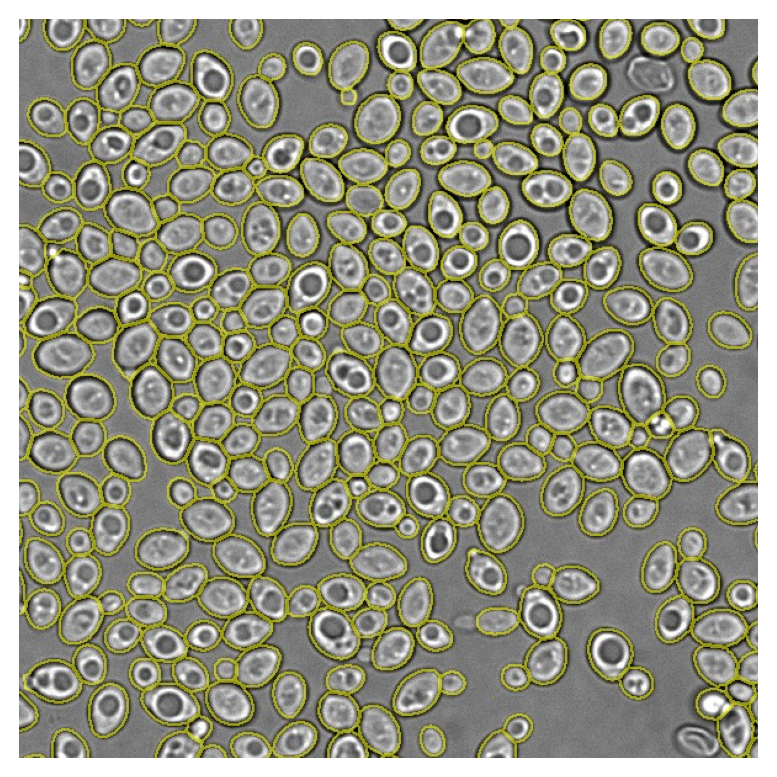

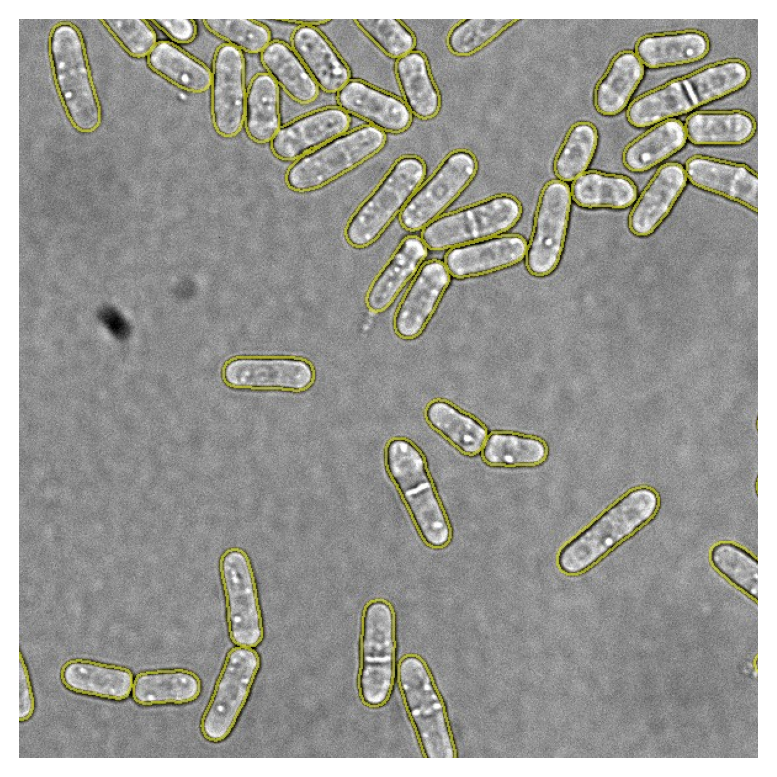

In [ ]:
# | code-fold: true
# | code-summary: "Code to plot the overlays"
# | label: fig-overlays
# | layout-ncol: 2
# | fig-cap: "Cellpose-SAM outlines on brightfield. Each panel is a 600 × 600 crop from the center of one field."
# | fig-subcap:
# |   - "*S. cerevisiae* BY4743, well K01"
# |   - "*S. pombe* SP286, well K05"
# | fig-alt:
# |   - "Center crop of a brightfield field of ovoid budding yeast with yellow cell outlines."
# |   - "Center crop of a brightfield field of rod-shaped fission yeast with yellow cell outlines."

import re
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from analysis.bucket_io import OVERLAYS_SUBDIR
from analysis.dataset import ensure_dataset
from analysis.infra import BUCKET
from analysis.runner import modal_backend_available

QC_WELLS = ("K01", "K05")
QC_CROP = 600


def _well(name: str) -> str | None:
    match = re.search(r"(?:well[ _-]?)?([A-P])0*([1-9][0-9]?)", name, flags=re.IGNORECASE)
    if not match:
        return None
    return f"{match.group(1).upper()}{int(match.group(2)):02d}"


def _from_run(well: str) -> Path | None:
    for summary in run.results:
        path = summary.get("local_overlay")
        if not path:
            continue
        path = Path(path)
        name = str(summary.get("input", ""))
        if path.exists() and _well(name) == well:
            return path
    return None


def _from_local_derived(well: str) -> Path | None:
    overlay_dir = DATASET_DIR / "derived" / OVERLAYS_SUBDIR
    if not overlay_dir.is_dir():
        return None
    for path in sorted(overlay_dir.glob("*_overlay.jpg")):
        if _well(path.name) == well:
            return path
    return None


def _from_s3(well: str) -> Path | None:
    dest_dir = Path("scratch/segmentation_results")
    dest_dir.mkdir(parents=True, exist_ok=True)
    prefix = f"s3://{BUCKET}/datasets/{DATASET_ID}/derived/{OVERLAYS_SUBDIR}/"
    try:
        listed = subprocess.run(
            ["aws", "s3", "ls", prefix], check=True, capture_output=True, text=True
        )
    except (FileNotFoundError, subprocess.CalledProcessError):
        return None
    for line in listed.stdout.splitlines():
        name = line.split()[-1] if line.split() else ""
        if not (name.endswith("_overlay.jpg") and _well(name) == well):
            continue
        dest = dest_dir / name
        try:
            subprocess.run(
                ["aws", "s3", "cp", prefix + name, str(dest)],
                check=True,
                capture_output=True,
            )
        except (FileNotFoundError, subprocess.CalledProcessError):
            return None
        return dest if dest.exists() else None
    return None


def _from_published(well: str) -> Path | None:
    if modal_backend_available():
        return _from_s3(well)
    ensure_dataset(DATASET_ID, DATASET_DIR)
    return _from_local_derived(well)


def _center_crop(image: np.ndarray, size: int) -> np.ndarray:
    height, width = image.shape[:2]
    size = min(size, height, width)
    y0 = (height - size) // 2
    x0 = (width - size) // 2
    return image[y0 : y0 + size, x0 : x0 + size]


for well in QC_WELLS:
    overlay = _from_run(well) or _from_local_derived(well) or _from_published(well)
    if overlay is None:
        raise FileNotFoundError(
            f"No overlay for well {well}. Rerun the segmentation above or unpack "
            f"the published dataset so derived/{OVERLAYS_SUBDIR}/ is present."
        )
    fig, ax = plt.subplots()
    ax.imshow(_center_crop(plt.imread(overlay), QC_CROP))
    ax.set_axis_off()
    plt.show()

### Per-cell phenotyping outputs

Alongside the masks and overlays, the pipeline turns each segmented cell into a row of morphology measurements — area, eccentricity, axis lengths, and related features — using scikit-image regionprops. The code below concatenates these rows across all 64 images and joins them to the plate map, attaching a species label to every cell. This yields the per-cell morphology dataset for the analysis that follows, a preview of which is shown in @tbl-cells.

::: {.callout-note title="Where the measurements load from" collapse="true"}
By default (`MEASUREMENTS_SOURCE = "auto"`), the analysis loads the published full-plate table from S3 (Modal) or the Zenodo archive ([10.5281/zenodo.23377605](https://doi.org/10.5281/zenodo.23377605)), so downstream results do not depend on how many images you just segmented. Set it to `"run"` to use only this session's segmentation output.
:::

In [ ]:
# | code-fold: true
# | code-summary: "Code to load the per-cell measurements"
# | label: tbl-cells
# | tbl-cap: "Pooled per-cell measurements joined to the plate map (first five rows)."

import re
from pathlib import Path

import pandas as pd
from analysis.measurements import load_measurements

# "auto" loads the published full-plate table from S3 or Zenodo;
# "run" uses only the measurements returned by the segmentation above.
MEASUREMENTS_SOURCE = "auto"  # "auto" | "run" | "modal" | "zenodo"

if MEASUREMENTS_SOURCE == "run":
    measurements = run.measurements.copy()
else:
    measurements = load_measurements(DATASET_ID, source=MEASUREMENTS_SOURCE)


def _find_plate_map() -> Path:
    for candidate in (Path("plate-map.csv"), Path("../plate-map.csv")):
        if candidate.exists():
            return candidate
    raise FileNotFoundError("plate-map.csv not found next to the notebook or its parent.")


plate_map = pd.read_csv(_find_plate_map())


def well_from_name(name: str) -> str | None:
    """Pull a plate-well token (e.g. 'K01') from an NIS image name."""
    match = re.search(r"(?:well[ _-]?)?([A-P])0*([1-9][0-9]?)", name, flags=re.IGNORECASE)
    if not match:
        return None
    return f"{match.group(1).upper()}{int(match.group(2)):02d}"


measurements["well"] = measurements["image"].map(well_from_name)
labeled = measurements.merge(plate_map[["well", "species", "strain"]], on="well", how="left")

n_unmapped = int(labeled["species"].isna().sum())
if n_unmapped:
    print(
        f"Warning: {n_unmapped} cell(s) had no species match; check well_from_name vs. your filenames."
    )
print(f"{len(labeled)} cells across {labeled['species'].nunique()} species.")
labeled.head()

111216 cells across 2 species.


,image,label,area_um2,area_convex_um2,perimeter_um,eccentricity,solidity,axis_major_length_um,axis_minor_length_um,orientation,...,volume_um3,centroid_y,centroid_x,intensity_mean_brightfield,intensity_max_brightfield,intensity_min_brightfield,intensity_std_brightfield,well,species,strain
0,WellK01_PointK01_0000_Channelbrightfield_Seq0000,1,3.247969,3.327187,6.848097,0.833476,0.976190,2.796265,1.545093,1.557885,...,3.495314,4.390244,156.178862,8360.943089,12074.0,4180.0,1878.051340,K01,cerevisiae,BY4743
1,WellK01_PointK01_0000_Channelbrightfield_Seq0000,2,2.112500,2.693437,7.850978,0.987773,0.784314,4.305462,0.671226,-1.566048,...,1.015679,2.587500,603.537500,7888.650000,8531.0,7178.0,318.510247,K01,cerevisiae,BY4743
2,WellK01_PointK01_0000_Channelbrightfield_Seq0000,3,2.851875,2.931094,7.077907,0.922667,0.972973,3.147329,1.213606,1.557823,...,2.427147,3.537037,1195.759259,7629.027778,10633.0,4981.0,1402.505400,K01,cerevisiae,BY4743
3,WellK01_PointK01_0000_Channelbrightfield_Seq0000,4,15.025156,15.394844,14.139481,0.587677,0.975986,4.867268,3.938085,-0.026246,...,39.523367,15.298770,1928.912127,7511.982425,13169.0,3130.0,2136.657715,K01,cerevisiae,BY4743
4,WellK01_PointK01_0000_Channelbrightfield_Seq0000,5,6.548750,6.997656,9.633694,0.658290,0.935849,3.337724,2.512520,1.227397,...,11.032353,9.193548,409.491935,7759.399194,11136.0,4800.0,1387.045749,K01,cerevisiae,BY4743


### Shape alone separates the two species

The per-cell measurements are the pipeline's actual product, so the fair test is whether they support the analysis we would run next. Given nothing but per-cell shape, the two yeasts should separate: *S. cerevisiae* is an ovoid budding yeast, and *S. pombe* is a rod. A pipeline that failed this test wouldn’t be worth scaling.

First, we gate on cell area. Segmentation returns some objects that are not single cells: fragments and debris at the small end, and clumps that Cellpose resolved as a single mask at the large end (the largest object in the full-plate table is about 150 μm², more than 6 times the median S. cerevisiae cell). We keep objects between 5 and 100 μm², an area-equivalent circular diameter of 2.5–11.3 μm, which generously brackets a plausible single yeast cell.

In [5]:
# | code-fold: true
# | code-summary: "Code to set up the analysis and gate on cell area"

import arcadia_pycolor as apc
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

apc.plotly.setup()

GROUP_COL = "species"
REFERENCE = "cerevisiae"  # the species the others are compared against
POSITIVE = "pombe"  # the "positive" class for AUC
AREA_COL = "area_um2" if "area_um2" in labeled.columns else "area"
AREA_LABEL = "cell area (μm²)" if AREA_COL == "area_um2" else "cell area (px)"

# Plausible-single-cell gate. 5–100 μm² is an area-equivalent circular diameter of
# 2.5–11.3 μm: below it, debris and partial masks; above it, merged clumps.
MIN_AREA_UM2 = 5.0
MAX_AREA_UM2 = 100.0

measured = labeled.dropna(subset=[GROUP_COL, AREA_COL])
# The gate is written in μm², so it only applies when the pixel size was known.
in_gate = (
    measured[AREA_COL].between(MIN_AREA_UM2, MAX_AREA_UM2)
    if AREA_COL == "area_um2"
    else pd.Series(True, index=measured.index)
)
analysis_df = measured.loc[in_gate].copy()

present = list(analysis_df[GROUP_COL].unique())
groups = ([REFERENCE] if REFERENCE in present else []) + sorted(
    g for g in present if g != REFERENCE
)

# Italicized "S. pombe"-style labels and a stable color per species, from the plate map.
genus_by_species = plate_map.drop_duplicates(GROUP_COL).set_index(GROUP_COL)["genus"]
DISPLAY = {species: f"<i>{genus_by_species[species][0]}. {species}</i>" for species in groups}
COLORS = dict(
    zip(groups, [apc.aegean.hex_code, apc.amber.hex_code, apc.seaweed.hex_code], strict=False)
)

n_dropped = int((~in_gate).sum())
print(
    f"{len(analysis_df):,} of {len(measured):,} cells pass the "
    f"{MIN_AREA_UM2:g}–{MAX_AREA_UM2:g} μm² gate "
    f"({n_dropped:,} dropped, {n_dropped / len(measured):.2%})."
)
print(
    f"{len(groups)} species across {analysis_df['well'].nunique()} well(s) and "
    f"{analysis_df['image'].nunique()} image(s): {', '.join(groups)}"
)

110,497 of 111,216 cells pass the 5–100 μm² gate (719 dropped, 0.65%).


2 species across 16 well(s) and 64 image(s): cerevisiae, pombe


Next, we examine how cleanly the morphology separates the two species. We start with the joint distribution of cell area and eccentricity, the two features expected to carry most of the signal (@fig-area-ecc), then rank every shape feature by how well it separates the species on its own (@tbl-features).

In [6]:
# | code-fold: true
# | code-summary: "Code for the area-vs-eccentricity figure"
# | label: fig-area-ecc
# | fig-cap: "Joint distribution of cell area and eccentricity, with marginal box plots. Scatter points are a random subsample of 5,000 cells per species; boxes use every cell that passed the area gate."
# | fig-alt: "Scatter plot of cell area versus eccentricity with two largely non-overlapping clouds for budding yeast and fission yeast, and box plots along each axis."

# Every cell is used for the marginal boxes; the scatter shows a random subsample per
# species, since 112,000 overplotted markers read as two solid blobs (and bloat the page).
POINTS_PER_SPECIES = 5000
rng = np.random.default_rng(0)


def box_stats(values):
    """Quartiles and Tukey fences for a Plotly box trace built from precomputed statistics."""
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    iqr = q3 - q1
    return dict(
        q1=[q1],
        median=[median],
        q3=[q3],
        lowerfence=[max(values.min(), q1 - 1.5 * iqr)],
        upperfence=[min(values.max(), q3 + 1.5 * iqr)],
        mean=[values.mean()],
    )


fig = make_subplots(
    rows=2,
    cols=2,
    column_widths=[0.85, 0.15],
    row_heights=[0.15, 0.85],
    shared_xaxes=True,
    shared_yaxes=True,
    horizontal_spacing=0.02,
    vertical_spacing=0.02,
)

for species in groups:
    cells = analysis_df[analysis_df[GROUP_COL] == species]
    color = COLORS[species]

    shown = cells.iloc[
        rng.choice(len(cells), size=min(POINTS_PER_SPECIES, len(cells)), replace=False)
    ]
    fig.add_trace(
        go.Scattergl(
            x=shown[AREA_COL],
            y=shown["eccentricity"],
            mode="markers",
            showlegend=False,
            marker=dict(color=color, size=3, opacity=0.4, line=dict(width=0)),
            hovertemplate=f"{species}<br>area %{{x:.1f}} μm²<br>ecc. %{{y:.2f}}<extra></extra>",
        ),
        row=2,
        col=1,
    )
    # A legend-only proxy, so the key shows a full-size, full-opacity marker.
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            name=f"{DISPLAY[species]}  (n = {len(cells):,})",
            marker=dict(color=color, size=9),
        ),
        row=2,
        col=1,
    )

    box_kwargs = dict(
        showlegend=False,
        fillcolor=color,
        line=dict(color=apc.charcoal.hex_code, width=1),
        width=0.45,
        hoverinfo="skip",
    )
    fig.add_trace(
        go.Box(**box_stats(cells[AREA_COL].to_numpy()), y=[species], orientation="h", **box_kwargs),
        row=1,
        col=1,
    )
    fig.add_trace(
        go.Box(**box_stats(cells["eccentricity"].to_numpy()), x=[species], **box_kwargs),
        row=2,
        col=2,
    )

fig.update_xaxes(title_text=AREA_LABEL, range=[0, MAX_AREA_UM2], row=2, col=1)
fig.update_yaxes(title_text="eccentricity", range=[0, 1.02], row=2, col=1)
for row, col in ((1, 1), (2, 2)):  # the marginals borrow their scale from the scatter
    fig.update_xaxes(showticklabels=False, ticks="", showline=False, row=row, col=col)
    fig.update_yaxes(showticklabels=False, ticks="", showline=False, row=row, col=col)

fig.update_layout(
    width=720,
    height=560,
    title="Area and eccentricity split the panel into two populations",
    legend=dict(
        x=0.99, y=0.03, xanchor="right", yanchor="bottom", bgcolor="rgba(255,255,255,0.75)"
    ),
)
apc.plotly.style_plot(fig, monospaced_axes="xy", row=2, col=1)
fig.show()

The two clouds in @fig-area-ecc barely touch. *S. pombe* traces a tight arc, which is what fission yeast morphology predicts: it grows by extending its tips at roughly constant width, so a cell gets larger and more elongated at the same time, and area and eccentricity rise together over the cell cycle. *S. cerevisiae* instead fills a broad, rounder cloud that tails off toward buds with lower area and eccentricity. The marginal boxes show where the separation actually comes from. The area distributions overlap somewhat, since a large budding yeast is the size of a small fission yeast, while the eccentricity distributions hardly overlap at all.

### Ranking every shape feature

Area and eccentricity are two of the nine shape features the pipeline reports; the full set is listed in @tbl-features. To rank all of them, we use the area under the receiver operating characteristic (ROC) curve for each feature on its own: the probability that a randomly chosen *S. pombe* cell scores higher than a randomly chosen *S. cerevisiae* cell. An AUC of 0.5 means the feature is useless and 1.0 means the two distributions do not overlap at all. It's a rank statistic, so the long tails in these distributions do not distort it.

@tbl-features also reports a two-sided Mann–Whitney *$p$*-value on the well-level medians, not on the individual cells. The null hypothesis is that the well-median distributions of a given feature are the same in the two species. Cells from the same well share a field of view, a focus plane, and an illumination profile, so a test across all 110,497 cells would treat those shared conditions as independent observations and return *$p$* ≈ 0 for every feature. The table instead compares 16 well medians, eight per species. With eight versus eight, the smallest two-sided *$p$*-value is 1.6 × 10⁻⁴, and several features reach it because their well medians do not overlap. Those wells are technical replicates, so the test measures consistency across wells rather than a difference between the species.

In [7]:
# | code-fold: true
# | code-summary: "Code to rank shape features by how well each one separates the species"
# | label: tbl-features
# | tbl-cap: "Shape features ranked by how well each one separates the two species (AUC on cells; two-sided Mann–Whitney test on well medians)."

from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

# Shape only. Orientation is an arbitrary lab-frame angle, the centroids are positions, and
# the brightfield intensities describe illumination as much as they describe the cell.
FEATURES = {
    "area_um2": "area (μm²)",
    "area_convex_um2": "convex area (μm²)",
    "perimeter_um": "perimeter (μm)",
    "axis_major_length_um": "major axis (μm)",
    "axis_minor_length_um": "minor axis (μm)",
    "eccentricity": "eccentricity",
    "solidity": "solidity",
    "circularity": "circularity",
    "volume_um3": "volume (μm³)",
}
FEATURES = {col: label for col, label in FEATURES.items() if col in analysis_df.columns}

is_positive = (analysis_df[GROUP_COL] == POSITIVE).to_numpy()
well_medians = analysis_df.groupby(["well", GROUP_COL])[list(FEATURES)].median().reset_index()

rows = []
for col, label in FEATURES.items():
    auc = roc_auc_score(is_positive, analysis_df[col])
    _, p_well = mannwhitneyu(
        well_medians.loc[well_medians[GROUP_COL] == POSITIVE, col],
        well_medians.loc[well_medians[GROUP_COL] == REFERENCE, col],
        alternative="two-sided",
    )
    rows.append(
        {
            "feature": label,
            f"median, {REFERENCE}": round(analysis_df.loc[~is_positive, col].median(), 2),
            f"median, {POSITIVE}": round(analysis_df.loc[is_positive, col].median(), 2),
            # Flip AUCs below 0.5 so every feature is scored in its discriminating direction.
            "AUC": round(max(auc, 1 - auc), 3),
            "well-level p (two-sided)": f"{p_well:.1e}",
        }
    )

feature_stats = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
feature_stats

,feature,"median, cerevisiae","median, pombe",AUC,well-level p (two-sided)
0,eccentricity,0.61,0.93,0.995,1.6e-04
1,circularity,0.89,0.67,0.992,1.6e-04
2,major axis (μm),6.16,12.32,0.991,1.6e-04
3,perimeter (μm),18.06,28.91,0.979,1.6e-04
4,convex area (μm²),23.92,46.18,0.957,1.6e-04
5,area (μm²),23.13,44.47,0.956,1.6e-04
6,volume (μm³),74.36,141.01,0.886,1.6e-04
7,solidity,0.97,0.96,0.623,1.6e-04
8,minor axis (μm),4.80,4.68,0.547,3.8e-02


Among these features, eccentricity leads at an AUC of 0.995, with circularity and major-axis length close behind, as all three are measuring elongation. The size-based features score marginally lower (area 0.956 and volume 0.886). Volume trails area because it's estimated as a prolate spheroid, $\frac{4}{3} \pi a b^2$, which weights the minor axis twice, and the minor axis carries the least amount of species signal (AUC 0.547; medians 4.80 vs 4.68 μm).

## Discussion and conclusion

Pairing Cellpose-SAM with on-demand cloud GPU compute provides a robust way to do high-throughput single-cell segmentation and morphology-based phenotyping. On the two-species yeast panel, the pipeline segmented all 64 fields without a failure, and the per-cell shape measurements separated the two species. Because the segmentation step is the same whether it runs on one machine or across dozens of GPU containers, the pipeline scales smoothly from a handful of images to a full high-content screen.

Although we’ve only demonstrated the pipeline here on yeast, we expect it to carry over to other unicellular organisms and dissociated cultured cells relatively seamlessly. Cellpose-SAM is a generalist model, so segmentation should work on other microbes, protists, and cell types without retraining, and the file handling, parallel execution, and per-cell measurements don’t depend on the organism. Adapting the pipeline to a new cell type mostly comes down to making sure the cells fall within the 7.5–120 px diameter range that Cellpose-SAM handles well. While the cell diameter parameter is tunable, it simply rescales the image so that the specified diameter becomes 30 px. Thus, it can’t recover fine detail the optics didn’t capture. For accurate measurements of very small or very large cells, such as bacteria or large protists, we’d sooner change the magnification or the optical setup. The pipeline also works best on cells that can be segmented cleanly as individuals, so dense, overlapping colonies or tissue would require more care.

The most immediate extension is fluorescence. The same masks can read per-cell intensities from other channels, such as reporters, markers, and stains, thereby turning a shape-only readout into a multi-channel phenotyping assay. We do this routinely in-house, but left it out here only to keep the demo focused on the segmentation-and-scaling pattern rather than any one biological readout. The masks are also a good starting point for richer phenotyping, whether that's CellProfiler-style texture and intensity features or embeddings from pretrained vision models, both of which run on the images and masks the pipeline already produces.

A few limits are worth keeping in mind. We judge segmentation by visual QC and by the internal consistency of the derived measurements rather than against ground-truth labels. Moreover, the scaled path relies on paid GPU compute and cloud storage. And although the local compute path runs the same plate without these paid accounts, it’s slow enough to be impractical beyond a handful of images.

Taken together, the demo shows a segmentation-and-phenotyping pattern that resolves real morphological differences, runs quickly and inexpensively at screen scale, and should carry from this yeast panel to other organisms and richer phenotypes.

## Methods {#sec-methods}

### Sample preparation

We imaged two wild-type budding and fission yeast strains: *S. cerevisiae* BY4743 and *S. pombe* SP286, respectively. Strains were streaked from freezer stocks onto agar plates. *S. cerevisiae* was grown in YPD + 2% dextrose and *S. pombe* in YES + 2% dextrose, and both were incubated for 2 days at 30 °C. For each strain, four colonies (biological replicates) were picked and grown as 5 mL overnight liquid cultures in a round-bottom 24-well plate (MTC Bio, #WBB3224433), with 4.5 mm glass beads (Zymo Research, #50-444-634) in each well to keep cells in suspension. Each biological replicate was paired with a technical replicate, giving eight wells per species. Cells were transferred to a glass-bottom, 384-well plate (Cellvis, Product #P384-1.5H-N) for imaging.

### Image acquisition

We acquired the images on a Nikon system with NIS-Elements JOBS. Each of the 16 wells was imaged at four fields in a 2 × 2 grid, yielding 64 brightfield ND2 files. A representative file (@tbl-nd2-meta) was acquired with a Plan Apo λD 40× objective (NA 0.95), a pixel size of 0.1625 μm, and a 0.01 s exposure. Those settings are consistent across the plate, and we use the pixel size to convert spatial measurements from pixels to micrometers.

### Software

We ran the published notebook on Python 3.12. Segmentation uses Cellpose-SAM via cellpose 4.2.1.1 and `arcadia-microscopy-tools` 0.5.0. Downstream analysis uses scikit-image 0.26.0 [@vanderwalt2014scikit], SciPy 1.18.0 [@virtanen2020scipy], scikit-learn 1.9.1 [@pedregosa2011scikit], and Plotly 6.9.0 [@plotly]. Modal workers run the same stack in a Debian slim image (`python_version="3.12"`) under modal 1.5.3. Versions are pinned in `uv.lock`.

<!-- ## Data availability

The raw ND2s and precomputed `derived/` artifacts (masks, overlays, and per-cell measurement tables) are archived at [10.5281/zenodo.23377605](https://doi.org/10.5281/zenodo.23377605).  -->

<!-- ## Appendix {#sec-appendix}

`SegmentConfig` knobs forwarded to Cellpose-SAM, plus the Modal scale-out parameters (@tbl-segment-config). We keep the defaults, which match a typical brightfield yeast field — including `diameter=None` (30 px) and `cellprob_threshold=0.0`. Change them in `run_demo(...)` if your cells differ. We cap `max_containers` at 16 as a courtesy on a shared 100-GPU organizational limit; @tbl-benchmark reports runs above that cap.

| Parameter | Default | Role |
| --- | --- | --- |
| `diameter` | `None` (30 px) | Expected cell diameter in pixels |
| `flow_threshold` | `0.4` | Mask quality filter (higher is stricter) |
| `cellprob_threshold` | `0.0` | Cell-probability cutoff (higher yields fewer, more confident masks) |
| `percentile_low` / `percentile_high` | `0.1` / `99.9` | Contrast-stretch window after the DoG bandpass |
| `dog_sigma_low` / `dog_sigma_high` | `1.6` / `16.0` | Difference-of-Gaussians sigmas (pixels) before segmentation; `None` skips the filter |
| `gpu` | `L4` | Modal GPU type |
| `max_containers` | `16` | Ceiling on concurrent GPU workers |

: Segmentation and scale-out parameters {#tbl-segment-config} -->
